#Prequisites
Please install Python and required libraries for this exercise, or do it in google colab.

We recommend that you use either [PyTorch](https://pytorch.org/get-started/locally/) or [TensorFlow](https://www.tensorflow.org/learn)

The import statements of the solution we prepared are specified below, however feel free to use any other library.


## Data
The data is gained from sequencing data of the microbiome in humans colon. Basically different DNA fragments can be matched to the same species due to high variety of bacterial DNA, so starting from sequencing data of the complete mix of bacterial species from the colon, different fragments are matched to species Pan-genomes to identify different species.
In the processing, the sequences were mapped to bacteria species and normalized such that , these values describe a normalized quantitative measure.
Additionally, the following columns are provided:
- the first column is just an index generated in pseudoanonymization
- health status: 0 is healthy, 1 is colorectal cancer
- gender: 0 is female, 1 is male
- bmi is the body mass index
- age is, well, age

In [55]:
# We used these packages for our solution, you might use others
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve

from sklearn.linear_model import LogisticRegression

#1)
Read in the data and perform any cleaning you find necessary. You don't have to do any normalization.

Then give a short overview of the cohort:
- How many healthy and how many colorectal cancer patients are there? What accuracy would a model get that always predicts the majority class?
- Compare age, BMI and gender between the two groups (a table or a small plot is enough).

(2 points)

(110, 888)
health_status
1    57
0    53
Name: count, dtype: int64
0.5181818181818182


<Axes: xlabel='health_status', ylabel='gender'>

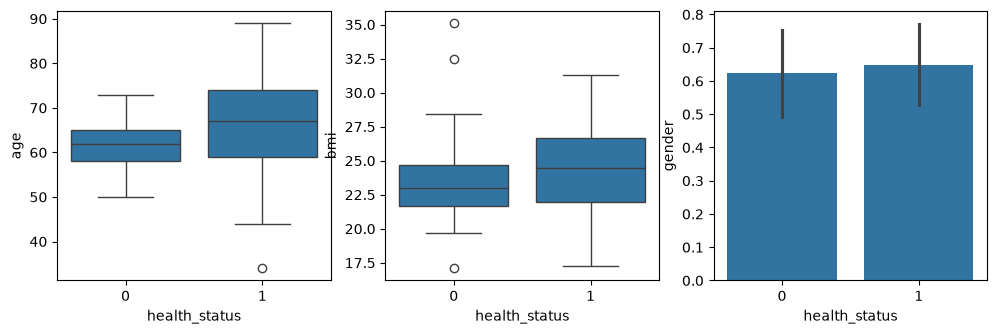

In [ ]:
# Read the data
df = pd.read_csv("microbiome_exercise_data.csv")
print(df.shape)
df.head()

# Do any data cleaning you feel is necessary (data is normalized already)
counts = df['health_status'].value_counts()
print(counts)                          
print(counts.max() / counts.sum())    

# Overview of the cohort
df.groupby('health_status').agg(
    age_mean=('age', 'mean'), age_std=('age', 'std'),
    bmi_mean=('bmi', 'mean'), bmi_std=('bmi', 'std'),
    male_share=('gender', 'mean'),    
)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
sns.boxplot(data=df, x='health_status', y='age', ax=ax[0])
sns.boxplot(data=df, x='health_status', y='bmi', ax=ax[1])
sns.barplot(data=df, x='health_status', y='gender', ax=ax[2])

print(
    "The BMI and gender are between both groups (healthy and cancer) relatively similiar as both groups include around 60% males and a BMI around ~24. However the patients with cancer tend to be more older and are scattered around more (~45 - ~90)"
)

# 2)
Explore the bacteria abundances. (2 points)

- Select the 20 bacteria species with the highest variance and plot a correlation heatmap of them.
- Find the 5 species whose mean abundance differs most between healthy (health_status = 0) and cancer (health_status = 1) patients and show their abundances in boxplots, split by health status.

In [57]:
# Correlation heatmap of the 20 most variable species

# Boxplots of the 5 species that differ most between the groups

#3)
Look at the structure of the data without using the labels. (3 points)

- Reduce the bacteria abundances to 2 dimensions with PCA and with t-SNE and plot both side by side, colouring the samples by health_status. How much variance do the first two principal components explain?
- Run k-means with k = 2 on the bacteria abundances and compare the resulting clusters with health_status (e.g. with `pd.crosstab`).

Do the clusters recover the disease label? Why or why not? (2-3 sentences)

In [58]:
# PCA and t-SNE

In [59]:
# k-means and comparison with health_status

#4)
Train a MLP (Multilayer Perceptron) on the data to classify the health_status based on the given variables/features. We provide you the full implementation: the network and the function `train_model`, which trains a network and returns the training and test loss and accuracy of every epoch. You don't have to change it.

Your tasks:

a) For each `nn.Linear` layer of the network we defined, write down the shape of its weight matrix W and its bias vector b (remember from the lecture: a layer computes h = a(Wx + b)). Use them to calculate by hand how many parameters the network has to learn, and show your calculation. Check your result with `sum(p.numel() for p in model.parameters())`.
How does this number compare to the number of patients in the training set? How many parameters does a logistic regression on the same features have? What do you expect from this for overfitting? (1 point)

b) Train the network and plot the training and test loss over the epochs in one figure, and the training and test accuracy in a second figure. Does the model overfit? If so, from which epoch on, and how can you see it in the plots? (2 points)

c) Define a smaller network with only one hidden layer of 5 neurons, train it with `train_model` and plot its curves in the same way. Calculate its number of parameters as in a), and compare it to the first network: how do the curves and the final test accuracy change? (1 point)

(4 points)

In [60]:
# Extract features and target labels
X = df.drop('health_status', axis=1).values
y = df['health_status'].values

# Convert to PyTorch tensors
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.long)

# Split the data into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=9, stratify=y_tensor)

input_dim = X_train.shape[1]

# Define the neural network: layers of neurons, each computing a weighted sum followed by an activation
model = nn.Sequential(
    nn.Linear(input_dim, 50),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(50, 50),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(50, 2)
)


def train_model(model, num_epochs=1000, lr=0.01):
    """Trains the model on the training set and returns the loss and accuracy of every epoch."""
    # The loss measures the error of the predictions (log-loss, as in logistic regression)
    criterion = nn.CrossEntropyLoss()
    # The optimizer adjusts the weights step by step to reduce the loss
    optimizer = optim.SGD(model.parameters(), lr=lr)

    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

    for epoch in range(num_epochs):
        # Learning step: predict the training patients, compute the error and adjust the weights
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(X_train), y_train)
        loss.backward()
        optimizer.step()

        # Evaluate the current model on the training and test set (no learning here)
        model.eval()
        with torch.no_grad():
            train_outputs = model(X_train)
            test_outputs = model(X_test)
            history['train_loss'].append(criterion(train_outputs, y_train).item())
            history['test_loss'].append(criterion(test_outputs, y_test).item())
            history['train_acc'].append(accuracy_score(y_train, train_outputs.argmax(dim=1)))
            history['test_acc'].append(accuracy_score(y_test, test_outputs.argmax(dim=1)))

        if (epoch+1) % 100 == 0:
            print(f"Epoch {epoch+1}/{num_epochs} | train loss {history['train_loss'][-1]:.4f} | test loss {history['test_loss'][-1]:.4f} "
                  f"| train acc {history['train_acc'][-1]:.3f} | test acc {history['test_acc'][-1]:.3f}")

    return history

TypeError: can't convert np.ndarray of type numpy.object_. The only supported types are: float64, float32, float16, complex64, complex128, int64, int32, int16, int8, uint64, uint32, uint16, uint8, and bool.

In [ ]:
# a) Describe the network and count its parameters

In [ ]:
# b) Train the network and plot the loss and accuracy curves
history = train_model(model)

In [ ]:
# c) Define, train and evaluate a smaller network

#5)
Evaluate the MLP on the test set. (3 points)

- Compute the confusion matrix. From the TP, FP, TN and FN compute sensitivity, specificity and precision yourself (don't use a library function for these three).
- Calculate the AUC and plot the ROC curve.

Your model should have around 60% or more accuracy. In some random splits you might get lower results, for this exercise just rerun the training in that case.

Imagine the model is used to screen people for colorectal cancer. Which is more important here, sensitivity or specificity? How would you change the decision threshold of 0.5 to account for that? (2-3 sentences)

In [ ]:
# Calculate performance metrics here

#6)
Train a logistic regression classifier on the same training data and evaluate it with cross-validation. (5 points)

a) Use 5-fold stratified cross-validation (`StratifiedKFold` and `cross_val_score` with `scoring='roc_auc'`) on the **training set** to evaluate `LogisticRegression`. Report the mean and standard deviation of the AUC over the folds. Why is this estimate more reliable than the result of a single train/test split? (2 points)

b) Logistic regression has a parameter `C` that controls regularization: it adds a penalty that keeps the coefficients small. A smaller `C` means a stronger penalty, i.e. a simpler model that is less likely to overfit; a larger `C` means a weaker penalty. Repeat the cross-validation from a) for `C = [0.001, 0.01, 0.1, 1, 10, 100]` and pick the value with the best mean AUC. (1 point)

c) Train the logistic regression with the best `C` on the whole training set and evaluate it on the test set (accuracy and AUC) as you did for the MLP. Compare both models: which one generalizes better? Use the difference between training and test performance and your loss curves from task 4 to argue which model overfits more. Why could a simpler model be enough when there are relatively few patients compared to the 437 features? (2 points)

In [ ]:
# a) Cross-validation of the logistic regression classifier

In [ ]:
# b) Choose C with cross-validation

In [ ]:
# c) Train the final logistic regression classifier, evaluate it on the test set and compare to MLP